# Laser power budget: resonant optical Bloch response

For the steady-state, closed two-level optical Bloch model on resonance,
\[
\boxed{\rho_{ee}(s_0)=\frac{s_0/2}{1+s_0}=\frac{s_0}{2(1+s_0)}}\,,\qquad
s_0=\frac{I}{I_{\mathrm{sat}}}=\frac{2|\Omega|^2}{\Gamma^2}\geq0.
\]
Here $\Gamma$ is the total spontaneous population decay rate. The saturation parameter is dimensionless. This is the resonant **two-level** response, with no additional shelving state or repump model.

- **Weak excitation:** $\rho_{ee}\simeq s_0/2$, so fluorescence is approximately proportional to laser intensity.
- **At $s_0=1$:** $\rho_{ee}=1/4$, which is half of the limiting population.
- **Strong excitation:** $\rho_{ee}\rightarrow1/2$. The emitted-photon rate is $R_{\mathrm{sc}}=\Gamma\rho_{ee}$, with limiting rate $\Gamma/2$.

The response is monotonic and bends downward:
\[
\frac{d\rho_{ee}}{ds_0}=\frac{1}{2(1+s_0)^2}>0,\qquad
\frac{d^2\rho_{ee}}{ds_0^2}=-\frac{1}{(1+s_0)^3}<0.
\]
Thus extra laser power gives progressively smaller population increases. The linear plot resolves the initial saturation; the logarithmic plot spans weak to strong excitation.

In [8]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter, NullFormatter
from matplotlib.font_manager import FontProperties, findfont
from IPython.display import display

# Figures: Arial, 18 pt, 8.2 x 5.2 inches, editable SVG text.
FIGURE_SIZE = (8.2, 5.2)
LINEAR_S0_LIMITS = (0.0, 20.0)
LOG_S0_LIMITS = (1e-3, 1e3)
PLOT_STYLE = {
    'font.family': 'Arial', 'font.size': 18,
    'axes.labelsize': 18, 'axes.titlesize': 18,
    'xtick.labelsize': 18, 'ytick.labelsize': 18,
    'legend.fontsize': 18,
    'mathtext.fontset': 'custom', 'mathtext.rm': 'Arial',
    'mathtext.it': 'Arial:italic', 'mathtext.bf': 'Arial:bold',
    'svg.fonttype': 'none', 'svg.image_inline': True,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.linewidth': 1.0,
}
BLUE = '#0072B2'
findfont(FontProperties(family='Arial'), fallback_to_default=False)

# Supports running from either the repository root or the notebook directory.
working_dir = Path.cwd()
NOTEBOOK_DIR = working_dir if working_dir.name == 'CONCEPTS' else working_dir/'CONCEPTS'
OUTPUT_DIR = NOTEBOOK_DIR/'laser_power_budget_results'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('SVG export directory:', OUTPUT_DIR.resolve())

SVG export directory: /Users/yiyangzhi/GIT/integrated_trapped_ions/CONCEPTS/laser_power_budget_results


In [9]:
def resonant_excited_population(s0):
    """Steady-state excited-state population for the resonant closed two-level OBE."""
    s = np.asarray(s0, dtype=float)
    if np.any(~np.isfinite(s)) or np.any(s < 0):
        raise ValueError('s0 must be finite and nonnegative')
    return 0.5*s/(1+s)


def saturation_for_plateau_fraction(fraction):
    """Intensity in units of I_sat required to reach a fraction of the rho_ee=1/2 plateau."""
    f = np.asarray(fraction, dtype=float)
    if np.any(~np.isfinite(f)) or np.any((f < 0) | (f >= 1)):
        raise ValueError('Plateau fraction must be in [0, 1)')
    return f/(1-f)


# Exact benchmarks and inverse check for the power-budget interpretation.
np.testing.assert_allclose(resonant_excited_population([0., 1., 9., 99.]), [0., .25, .45, .495])
plateau_fractions = np.array([.5, .8, .9, .95, .99])
required_s0 = saturation_for_plateau_fraction(plateau_fractions)
np.testing.assert_allclose(2*resonant_excited_population(required_s0), plateau_fractions)
print('Population benchmarks and inverse power-budget calculation verified.')

Population benchmarks and inverse power-budget calculation verified.


## Linear saturation curve

The dashed line marks the limiting population $1/2$. The points at $s_0=1$ and $s_0=9$ mark 50% and 90% of that plateau, respectively. The population itself is dimensionless; it is not expressed in dB.

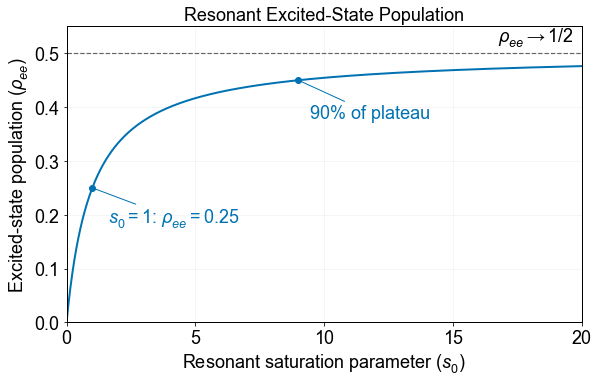

Saved: /Users/yiyangzhi/GIT/integrated_trapped_ions/CONCEPTS/laser_power_budget_results/resonant_excited_population_linear.svg


In [10]:
s0_linear = np.linspace(*LINEAR_S0_LIMITS, 1001)
rho_linear = resonant_excited_population(s0_linear)

with plt.rc_context(PLOT_STYLE):
    linear_figure, ax = plt.subplots(figsize=FIGURE_SIZE, constrained_layout=True)
    ax.plot(s0_linear, rho_linear, color=BLUE, lw=2.0)
    ax.axhline(.5, color='.4', lw=1.2, ls='--')
    ax.text(LINEAR_S0_LIMITS[1]-.3, .507, r'$\rho_{ee}\rightarrow1/2$',
            ha='right', va='bottom', fontsize=18)
    ax.plot([1., 9.], [.25, .45], 'o', color=BLUE, ms=6)
    ax.annotate(r'$s_0=1$: $\rho_{ee}=0.25$', xy=(1., .25), xytext=(16, -35),
                textcoords='offset points', color=BLUE, fontsize=18,
                arrowprops=dict(arrowstyle='-', color=BLUE, lw=1))
    ax.annotate('90% of plateau', xy=(9., .45), xytext=(12, -38),
                textcoords='offset points', color=BLUE, fontsize=18,
                arrowprops=dict(arrowstyle='-', color=BLUE, lw=1))
    ax.set(xlim=LINEAR_S0_LIMITS, ylim=(0, .55),
           xlabel=r'Resonant saturation parameter ($s_0$)',
           ylabel=r'Excited-state population ($\rho_{ee}$)',
           title='Resonant Excited-State Population')
    ax.set_xticks([0, 5, 10, 15, 20])
    ax.set_yticks(np.arange(0, .51, .1))
    ax.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))
    ax.grid(alpha=.18, lw=.7)
    linear_svg = OUTPUT_DIR/'resonant_excited_population_linear.svg'
    linear_figure.savefig(linear_svg, bbox_inches='tight')
    display(linear_figure)
    plt.close(linear_figure)

pd.DataFrame({'s0': s0_linear, 'rho_ee': rho_linear, 'fraction_of_plateau': 2*rho_linear}).to_csv(
    OUTPUT_DIR/'resonant_excited_population_linear.csv', index=False)
print('Saved:', linear_svg.resolve())

## Weak to strong excitation on a logarithmic saturation axis

Only the horizontal axis is logarithmic. The vertical axis is the same excited-state population as above. This view makes the linear low-power regime and the strong-driving plateau visible over six orders of magnitude in $s_0$.

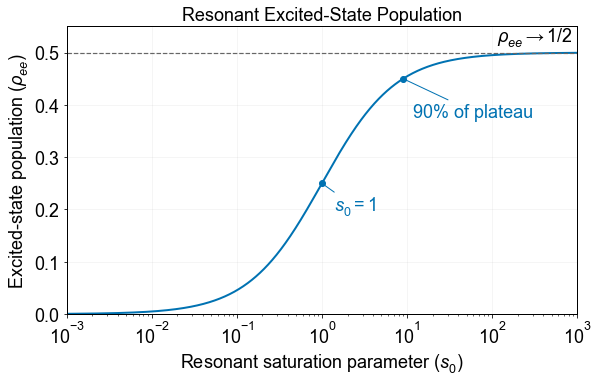

Saved: /Users/yiyangzhi/GIT/integrated_trapped_ions/CONCEPTS/laser_power_budget_results/resonant_excited_population_log.svg


In [11]:
s0_log = np.geomspace(*LOG_S0_LIMITS, 1501)
rho_log = resonant_excited_population(s0_log)

with plt.rc_context(PLOT_STYLE):
    log_figure, ax = plt.subplots(figsize=FIGURE_SIZE, constrained_layout=True)
    ax.semilogx(s0_log, rho_log, color=BLUE, lw=2.0)
    ax.axhline(.5, color='.4', lw=1.2, ls='--')
    ax.text(LOG_S0_LIMITS[1]/1.15, .507, r'$\rho_{ee}\rightarrow1/2$',
            ha='right', va='bottom', fontsize=18)
    ax.plot([1., 9.], [.25, .45], 'o', color=BLUE, ms=6)
    ax.annotate(r'$s_0=1$', xy=(1., .25), xytext=(12, -28),
                textcoords='offset points', color=BLUE, fontsize=18,
                arrowprops=dict(arrowstyle='-', color=BLUE, lw=1))
    ax.annotate('90% of plateau', xy=(9., .45), xytext=(10, -38),
                textcoords='offset points', color=BLUE, fontsize=18,
                arrowprops=dict(arrowstyle='-', color=BLUE, lw=1))
    ax.set(xlim=LOG_S0_LIMITS, ylim=(0, .55),
           xlabel=r'Resonant saturation parameter ($s_0$)',
           ylabel=r'Excited-state population ($\rho_{ee}$)',
           title='Resonant Excited-State Population')
    ax.set_yticks(np.arange(0, .51, .1))
    ax.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.grid(which='major', alpha=.18, lw=.7)
    log_svg = OUTPUT_DIR/'resonant_excited_population_log.svg'
    log_figure.savefig(log_svg, bbox_inches='tight')
    display(log_figure)
    plt.close(log_figure)

pd.DataFrame({'s0': s0_log, 'rho_ee': rho_log, 'fraction_of_plateau': 2*rho_log}).to_csv(
    OUTPUT_DIR/'resonant_excited_population_log.csv', index=False)
print('Saved:', log_svg.resolve())

## Power needed to approach the plateau

Define $f=\rho_{ee}/(1/2)=2\rho_{ee}$. Then
\[
f=\frac{s_0}{1+s_0}\quad\Rightarrow\quad s_0=\frac{f}{1-f}.
\]
For a fixed beam geometry and coupling, $s_0\propto I\propto P$. Therefore 90%, 95%, and 99% of the limiting population require $s_0=9$, 19, and 99, respectively. The limit $\rho_{ee}=1/2$ is approached asymptotically; it is not reached at finite $s_0$.

In [12]:
budget_table = pd.DataFrame({
    'fraction_of_plateau': plateau_fractions,
    'percent_of_plateau': 100*plateau_fractions,
    'required_s0': required_s0,
    'rho_ee': resonant_excited_population(required_s0),
})
display(budget_table)
budget_table.to_csv(OUTPUT_DIR/'resonant_population_power_budget.csv', index=False)

,fraction_of_plateau,percent_of_plateau,required_s0,rho_ee
0,0.50,50.0,1.0,0.250
1,0.80,80.0,4.0,0.400
2,0.90,90.0,9.0,0.450
3,0.95,95.0,19.0,0.475
4,0.99,99.0,99.0,0.495


## 4. Saturation intensities and required power

Using the strongest E1 Zeeman components and the parameters in the supplied table,
\[
\boxed{I_{\mathrm{sat,eff}}=\frac{\pi hc}
{3\lambda^3\tau_e\beta_{eg}|C_{eg}|^2}}.
\]
Here $\tau_e$ is the upper-state lifetime, $\beta_{eg}$ the branching fraction of the transition, and $\lvert C_{eg}\rvert^2$ its squared Zeeman coupling coefficient.

| Parameter | 422 nm | 1092 nm | 1033 nm |
|:--|--:|--:|--:|
| Upper state | $5P_{1/2}$ | $5P_{1/2}$ | $5P_{3/2}$ |
| Excited lifetime (ns) | 7.39 | 7.39 | 6.63 |
| Branching fraction $\beta_{eg}$ | 0.94498 | 0.05502 | 0.0531 |
| Maximum $\lvert C_{eg}\rvert^2$ | $2/3$ | $1/2$ | $2/3$ |
| $I_{\mathrm{sat,eff}}$ (mW/cm²) | 59.46 | 78.58 | 80.41 |
| $P$ at $s_0=4$, $w_0=10\;\mu\mathrm{m}$ | 0.374 µW | 0.494 µW | 0.505 µW |

For a circular Gaussian beam, $w_0$ is the **1/e² intensity radius**, not the diameter:
\[
I(r)=I_0e^{-2r^2/w_0^2},\qquad I_0=\frac{2P}{\pi w_0^2},\qquad
s_0=\frac{I_0}{I_{\mathrm{sat,eff}}}.
\]
Therefore the required beam power on resonance is
\[
\boxed{P(s_0,w_0)=\frac{\pi w_0^2}{2}\,s_0 I_{\mathrm{sat,eff}}}.
\]
Power is proportional to $s_0$ and to $w_0^2$. These are powers in the beam at the stated waist; no optical transmission loss is included.

### Calculator

Enter **$s_0$** and **$w_0$ in µm** below. Press **Enter**, leave the input field, or click **Calculate** to display the updated Markdown table. The same $s_0$ and waist apply to all three wavelengths. Saturation intensities stay fixed; the required-power row changes.

In [13]:
from IPython.display import Markdown, display

# Inputs transcribed from the supplied table. Change these if updated atomic data are available.
POWER_TRANSITIONS = pd.DataFrame({
    'wavelength_nm': [422., 1092., 1033.],
    'upper_state': [r'$5P_{1/2}$', r'$5P_{1/2}$', r'$5P_{3/2}$'],
    'lifetime_ns': [7.39, 7.39, 6.63],
    'branching_fraction': [.94498, .05502, .0531],
    'clebsch_gordan_squared': [2/3, 1/2, 2/3],
    'cg_markdown': [r'$2/3$', r'$1/2$', r'$2/3$'],
})
PLANCK_H = 6.62607015e-34  # J s
LIGHT_C = 299792458.0     # m/s


def saturation_power_budget(s0, waist_um):
    """Required Gaussian beam power; waist_um is the circular 1/e^2 intensity radius."""
    s0, waist_um = float(s0), float(waist_um)
    if not np.isfinite(s0) or s0 < 0:
        raise ValueError('Enter a finite saturation parameter s0 >= 0.')
    if not np.isfinite(waist_um) or waist_um <= 0:
        raise ValueError('Enter a finite beam radius w0 > 0 in micrometres.')
    table = POWER_TRANSITIONS.copy()
    wavelength_m = table.wavelength_nm.to_numpy()*1e-9
    lifetime_s = table.lifetime_ns.to_numpy()*1e-9
    isat_w_m2 = np.pi*PLANCK_H*LIGHT_C / (
        3*wavelength_m**3*lifetime_s*table.branching_fraction.to_numpy()
        *table.clebsch_gordan_squared.to_numpy())
    table['isat_w_m2'] = isat_w_m2
    table['isat_mw_cm2'] = isat_w_m2*0.1  # 1 W/m^2 = 0.1 mW/cm^2
    table['s0'] = s0
    table['waist_um'] = waist_um
    table['required_power_uw'] = s0*isat_w_m2*np.pi*(waist_um*1e-6)**2/2*1e6
    return table


def saturation_power_markdown(table):
    """Return the calculated results in the same column layout as the supplied table."""
    s0 = float(table.s0.iloc[0])
    waist_um = float(table.waist_um.iloc[0])
    def row(label, values):
        return '| '+label+' | '+' | '.join(str(value) for value in values)+' |'
    lines = [
        f'### Calculated results: $s_0={s0:g}$, $w_0={waist_um:g}\\;\\mu\\mathrm{{m}}$',
        '',
        row('Parameter', [f'{wave:g} nm' for wave in table.wavelength_nm]),
        '|:--|--:|--:|--:|',
        row('Upper state', table.upper_state),
        row('Excited lifetime (ns)', [f'{value:g}' for value in table.lifetime_ns]),
        row(r'Branching fraction $\beta_{eg}$', [f'{value:g}' for value in table.branching_fraction]),
        row(r'Maximum $\lvert C_{eg}\rvert^2$', table.cg_markdown),
        row(r'$I_{\mathrm{sat,eff}}$ (mW/cm²)', [f'{value:.2f}' for value in table.isat_mw_cm2]),
        row(r'Required power $P$ (µW)', [f'{value:.4g}' for value in table.required_power_uw]),
    ]
    return '\n'.join(lines)


# Verify the reference table and the s0 * w0^2 power scaling.
reference_power_budget = saturation_power_budget(4., 10.)
np.testing.assert_allclose(reference_power_budget.isat_mw_cm2, [59.46, 78.58, 80.41], atol=.01)
np.testing.assert_allclose(reference_power_budget.required_power_uw, [.374, .494, .505], atol=.0005)
np.testing.assert_allclose(saturation_power_budget(8., 10.).required_power_uw,
                          2*reference_power_budget.required_power_uw)
np.testing.assert_allclose(saturation_power_budget(4., 20.).required_power_uw,
                          4*reference_power_budget.required_power_uw)
np.testing.assert_allclose(saturation_power_budget(0., 10.).required_power_uw, 0.)
print('Reference powers and linear/quadratic scaling verified.')

Reference powers and linear/quadratic scaling verified.


In [14]:
# Edit these defaults and rerun, or enter values in the interactive calculator below.
CALCULATOR_S0 = 1.0
CALCULATOR_WAIST_UM = 10.0

last_power_budget = saturation_power_budget(CALCULATOR_S0, CALCULATOR_WAIST_UM)
last_power_budget_markdown = saturation_power_markdown(last_power_budget)

try:
    import ipywidgets as widgets
except ImportError:
    # The calculator remains usable by editing the two values above and rerunning this cell.
    display(Markdown(last_power_budget_markdown))
else:
    saturation_input = widgets.FloatText(
        value=CALCULATOR_S0, description='s₀:', step=.1, continuous_update=False,
        style={'description_width': 'initial'}, layout=widgets.Layout(width='210px'))
    waist_input = widgets.FloatText(
        value=CALCULATOR_WAIST_UM, description='w₀ (µm):', step=.5, continuous_update=False,
        style={'description_width': 'initial'}, layout=widgets.Layout(width='230px'))
    calculate_button = widgets.Button(description='Calculate', button_style='primary',
                                      layout=widgets.Layout(width='120px'))
    power_calculator_output = widgets.Output(layout=widgets.Layout(width='100%'))

    def refresh_power_calculator(change=None):
        global last_power_budget, last_power_budget_markdown
        try:
            last_power_budget = saturation_power_budget(saturation_input.value, waist_input.value)
            last_power_budget_markdown = saturation_power_markdown(last_power_budget)
            content = last_power_budget_markdown
        except ValueError as error:
            content = f'**Please check the inputs:** {error}'
        # Update the Output widget directly so its Markdown table is also preserved on save.
        power_calculator_output.outputs = ({
            'output_type': 'display_data',
            'data': {'text/markdown': content, 'text/plain': content},
            'metadata': {},
        },)

    saturation_input.observe(refresh_power_calculator, names='value')
    waist_input.observe(refresh_power_calculator, names='value')
    calculate_button.on_click(refresh_power_calculator)
    refresh_power_calculator()
    power_calculator = widgets.VBox([
        widgets.HBox([saturation_input, waist_input, calculate_button]),
        power_calculator_output,
    ])
    display(power_calculator)